In [1]:
import tensorflow as tf
from sklearn.datasets import fetch_olivetti_faces
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

In [2]:
data = fetch_olivetti_faces()
X, y = data.images, data.target

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to C:\Users\hites\scikit_learn_data


In [3]:
X = X.reshape(-1, 64, 64, 1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [4]:
model = Sequential([
    Conv2D(32, (3, 3), activation='relu',
           input_shape=(64, 64, 1)),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(40, activation='softmax')
])

f:\BTech\DL\Lab\.venv\lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [5]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [6]:
model.fit(X_train, y_train, epochs=10)
model.evaluate(X_test, y_test)

Epoch 1/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.0219 - loss: 4.1161
Epoch 2/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.0688 - loss: 3.6378
Epoch 3/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.3656 - loss: 3.3150
Epoch 4/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.7219 - loss: 2.9421
Epoch 5/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.8531 - loss: 2.3873
Epoch 6/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.8969 - loss: 1.7579
Epoch 7/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.8844 - loss: 1.2351
Epoch 8/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9344 - loss: 0.8530
Epoch 9/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9500 - loss: 0.5644
Epoch 10/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9688 - loss: 0.3598
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8750 - loss: 0.7366


[0.7365903258323669, 0.875]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step


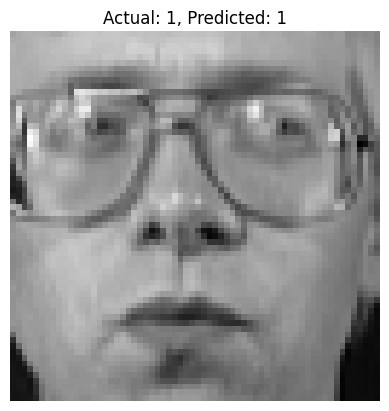

In [8]:
# Display test face and predicted person
import matplotlib.pyplot as plt
import numpy as np

i = 0
pred = model.predict(X_test[i:i+1]).argmax()

plt.imshow(X_test[i].squeeze(), cmap='gray')
plt.title(f"Actual: {y_test[i]}, Predicted: {pred}")
plt.axis('off')
plt.show()